# 06 · Figures

Every figure is drawn at its printed width (3.5 in = one IEEE column) so that the
font sizes set here are the font sizes on paper. Run after notebooks 01–05.

In [1]:
%run ./00_common.ipynb

root: <repository root>


In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap

INK, INK2, GRID = "#0b0b0b", "#52514e", "#d9d9d9"
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 600, "font.size": 8, "font.family": "DejaVu Sans",
    "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.4, "axes.axisbelow": True})
COL1 = 3.5
MODELS = ["Linear", "Ridge", "RandomForest", "XGBoost", "LightGBM", "lite-TFT"]
SHORT = {"Linear": "Linear", "Ridge": "Ridge", "RandomForest": "RF", "XGBoost": "XGB", "LightGBM": "LGBM", "lite-TFT": "lite-TFT"}
MCOL = {"Linear": "#9aa5b1", "Ridge": "#7b8794", "RandomForest": "#2f855a", "XGBoost": "#c05621", "LightGBM": "#b7791f", "lite-TFT": "#553c9a"}
TCOL = {24.0: "#c05621", 22.0: "#b7791f", 4.0: "#2b6cb0"}
PRETTY = {"soh": "SOH$_k$", "temp": "T$_{amb}$", "q_ref": "Q$_{ref}$", "Re": "R$_e$", "Rct": "R$_{ct}$",
          "slope10": "slope$_{10}$", "slope25": "slope$_{25}$", "std10": "std$_{10}$", "regen": "regen", "rul": "RUL"}
PRETTY.update({f"soh_lag{i}": f"lag{i}" for i in range(1, 11)})


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", pad_inches=0.02)
    plt.show()

### Fig. 1 — screening of all 34 cells (colour-blind-safe, hatched for greyscale)

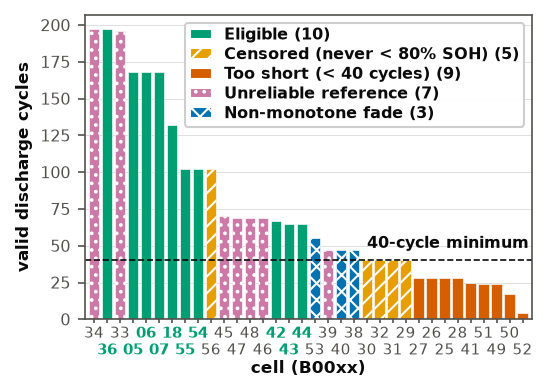

In [3]:
STATUS = [("eligible", "Eligible", "#009E73"), ("censored", "Censored (never < 80% SOH)", "#E69F00"),
          ("excluded: <", "Too short (< 40 cycles)", "#D55E00"), ("excluded: unreliable", "Unreliable reference", "#CC79A7"),
          ("excluded: non-monotone", "Non-monotone fade", "#0072B2")]
HATCH = {"Eligible": "", "Censored (never < 80% SOH)": "///", "Too short (< 40 cycles)": "",
         "Unreliable reference": "...", "Non-monotone fade": "xxx"}
scr = pd.read_csv(RESULTS / "screening.csv")
scr["cat"] = [next(n for key, n, _ in STATUS if s.startswith(key)) for s in scr["status"]]
scr = scr.sort_values("n_cycles", ascending=False).reset_index(drop=True)
col = {n: c for _, n, c in STATUS}
fig, ax = plt.subplots(figsize=(COL1, 2.45))
for i, r in scr.iterrows():
    ax.bar(i, r["n_cycles"], 0.8, color=col[r["cat"]], hatch=HATCH[r["cat"]], edgecolor="white", lw=0.3)
ax.axhline(40, color=INK, ls="--", lw=0.8)
ax.text(len(scr) - 0.5, 46, "40-cycle minimum", ha="right", va="bottom", fontsize=7.5, fontweight="bold")
ax.set_xticks(np.arange(len(scr)))
ax.set_xticklabels([b.replace("B00", "") for b in scr["battery"]], fontsize=7)
for i, t in enumerate(ax.get_xticklabels()):
    t.set_y(-0.055 if i % 2 else 0.0)
    if scr.loc[i, "cat"] == "Eligible":  # the 10 cohort cells: bold + green
        t.set_fontweight("bold"); t.set_color(col["Eligible"])
ax.tick_params(axis="x", length=2, pad=1.5); ax.set_xlim(-0.7, len(scr) - 0.3)
ax.set_xlabel("cell (B00xx)", labelpad=1, fontweight="bold"); ax.set_ylabel("valid discharge cycles", fontweight="bold"); ax.grid(axis="x", visible=False)
counts = scr["cat"].value_counts()
ax.legend([plt.Rectangle((0, 0), 1, 1, facecolor=c, hatch=HATCH[n], edgecolor="white") for _, n, c in STATUS],
          [f"{n} ({counts.get(n, 0)})" for _, n, _ in STATUS], loc="upper right", framealpha=0.95,
          handlelength=1.4, borderpad=0.3, labelspacing=0.25, prop={"weight": "bold"})
fig.tight_layout(pad=0.2); save(fig, "fig1_screening.png")

### Fig. 2 — Spearman correlation (R2-1)
Paper version: SOH$_k$ and lags 1, 5, 10 represent the near-identical lag block (all pairs rho >= 0.89). The full 20 x 20 matrix is saved as `figs/fig_corr_full.png`.

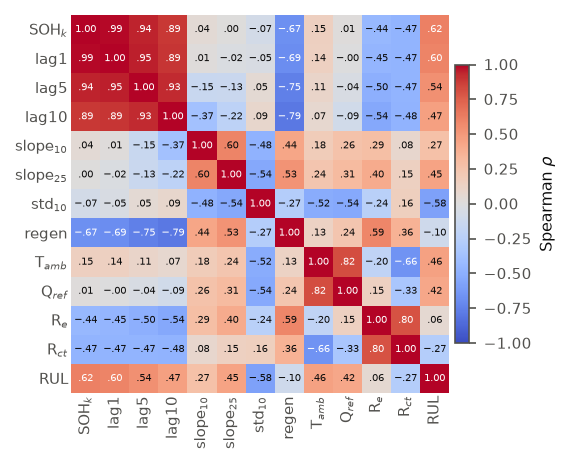

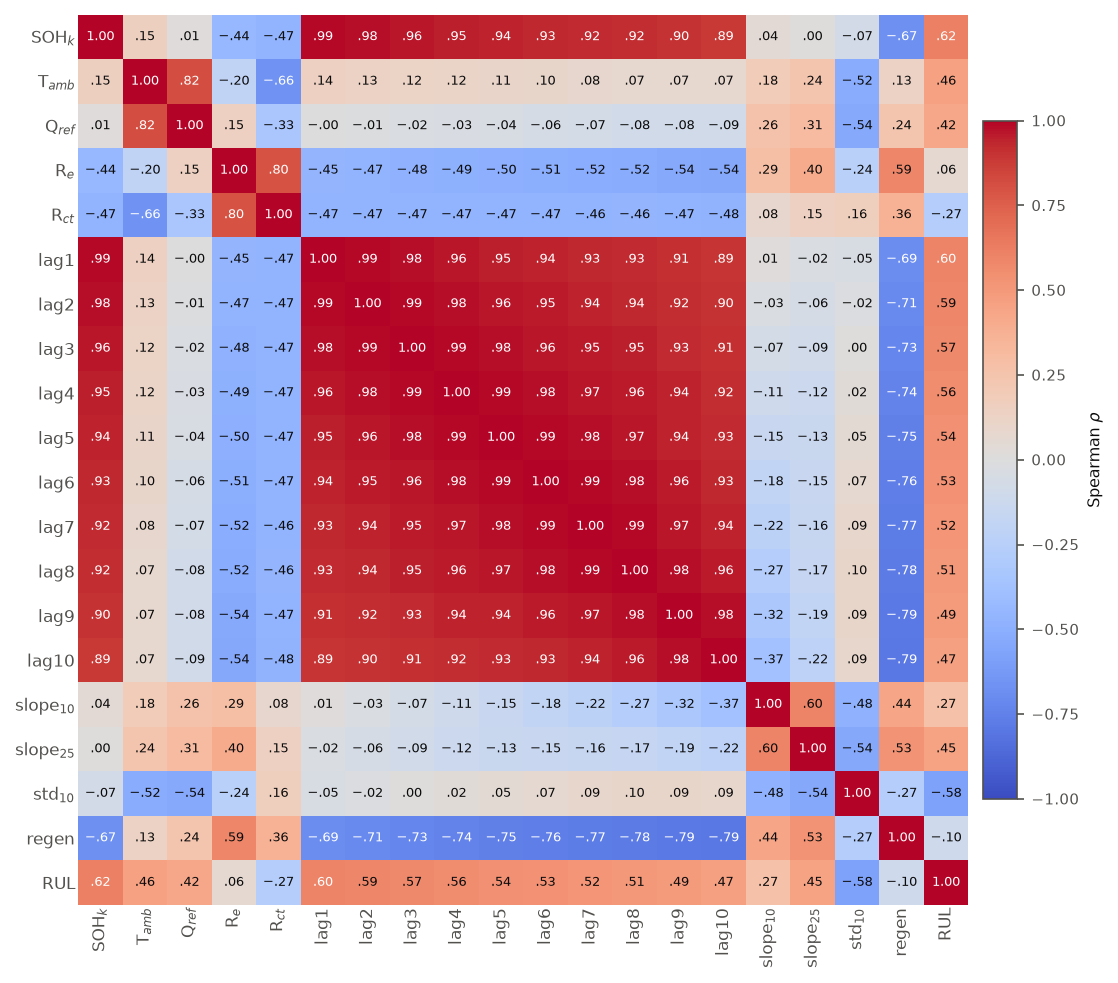

In [4]:
c = pd.read_csv(RESULTS / "feature_corr_spearman.csv", index_col=0)

def corr_plot(keys, name, size, fs_num, fs_lab):
    """Annotated correlation matrix, coolwarm palette."""
    m = c.loc[keys, keys].to_numpy()
    lab = [PRETTY.get(k, k) for k in keys]
    fig, ax = plt.subplots(figsize=size)
    im = ax.imshow(m, cmap="coolwarm", vmin=-1, vmax=1)
    for i in range(len(keys)):
        for j in range(len(keys)):
            v = m[i, j]
            ax.text(j, i, f"{v:.2f}".replace("0.", ".").replace("-.", "\u2212."), ha="center", va="center",
                    fontsize=fs_num, color="white" if abs(v) > 0.6 else INK)
    ax.set_xticks(range(len(lab))); ax.set_yticks(range(len(lab)))
    ax.set_xticklabels(lab, rotation=90, fontsize=fs_lab); ax.set_yticklabels(lab, fontsize=fs_lab)
    ax.tick_params(length=0, pad=1.5); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.015)
    cb.set_label("Spearman $\\rho$", fontsize=7.5); cb.ax.tick_params(labelsize=7)
    fig.tight_layout(pad=0.2); save(fig, name)

# paper version: SOH_k and lags 1, 5, 10 stand for the near-identical lag block (rho >= 0.89)
paper_keys = ["soh", "soh_lag1", "soh_lag5", "soh_lag10", "slope10", "slope25", "std10", "regen",
              "temp", "q_ref", "Re", "Rct", "rul"]
corr_plot(paper_keys, "fig_corr.png", (COL1, 3.15), 5.0, 7)
# full 20 x 20 matrix (all 19 features + label), two-column size, for the repository
corr_plot(list(c.index), "fig_corr_full.png", (7.16, 6.4), 6, 8)

### Fig. 3 — smoothed SOH of the 10-cell cohort

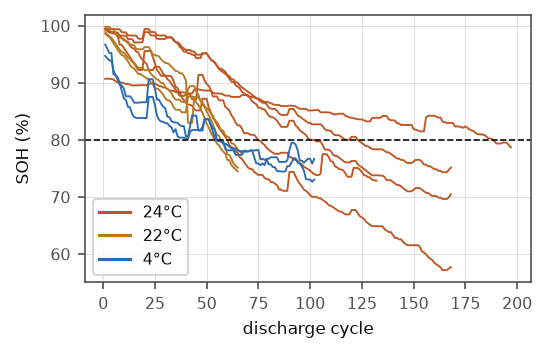

In [5]:
cells = load_cells(); scr2 = screen(cells, save=False)
fig, ax = plt.subplots(figsize=(COL1, 2.2))
for b in scr2[scr2.eligible].battery:
    g = cells[b]["df"]
    ax.plot(g["cycle"], g["soh_s"], color=TCOL[cells[b]["temp"]], lw=0.9)
ax.axhline(EOL_SOH_PRIMARY, color=INK, ls="--", lw=0.8)
ax.legend([Line2D([], [], color=c) for c in TCOL.values()], [f"{t:.0f}°C" for t in TCOL], loc="lower left")
ax.set_xlabel("discharge cycle"); ax.set_ylabel("SOH (%)")
fig.tight_layout(pad=0.2); save(fig, "fig2_cohort_soh.png")

### Figs. 4 and 5 — six-model comparison and same-cell controls (R2-2, R1-3)

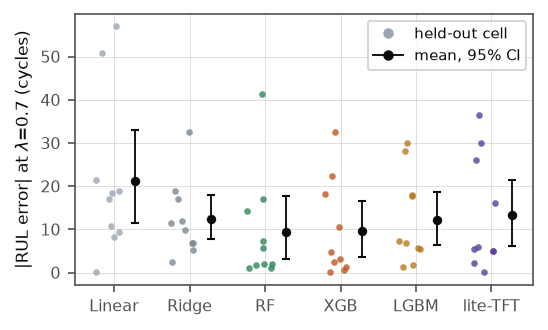

In [6]:
e = pd.read_csv(RESULTS / "nested_per_cell_errors.csv"); e = e[e.config == "nested"]
t = pd.read_csv(RESULTS / "tft_per_cell_errors.csv"); t = t[t.config == "trailing"]
e = pd.concat([e, t]); e = e[e["lambda"] == 0.7]
s = pd.read_csv(RESULTS / "nested_summary.csv"); s = s[(s.config == "nested") & (s["lambda"] == 0.7)].set_index("method")
ts = pd.read_csv(RESULTS / "tft_summary.csv"); ts = ts[(ts.config == "trailing") & (ts["lambda"] == 0.7)].set_index("method")
s = pd.concat([s, ts])
fig, a = plt.subplots(figsize=(COL1, 2.05))
rng = np.random.default_rng(0)
for i, m in enumerate(MODELS):
    y = e[e.method == m]["abs_err"].to_numpy()
    a.scatter(i + rng.uniform(-0.17, 0.17, len(y)) - 0.08, y, s=10, color=MCOL[m], alpha=0.8, lw=0)
    mu, lo, hi = s.loc[m, "MAE"], s.loc[m, "MAE_ci_lo"], s.loc[m, "MAE_ci_hi"]
    a.errorbar(i + 0.28, mu, yerr=[[mu - lo], [hi - mu]], fmt="o", color=INK, ms=3.5, lw=0.9, capsize=2)
a.set_xticks(range(len(MODELS))); a.set_xticklabels([SHORT[m] for m in MODELS])
a.set_ylabel("|RUL error| at $\\lambda$=0.7 (cycles)")
a.legend(handles=[Line2D([], [], marker="o", lw=0, color="#9aa5b1", ms=4, label="held-out cell"),
                  Line2D([], [], marker="o", color=INK, ms=4, lw=0.9, label="mean, 95% CI")], loc="upper right", fontsize=7)
fig.tight_layout(pad=0.2); save(fig, "fig_models_a.png")

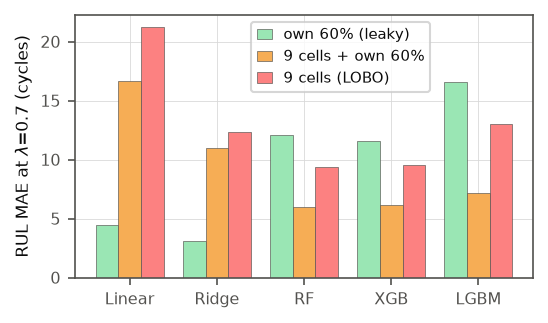

In [7]:
sc = pd.read_csv(RESULTS / "final_same_cell.csv"); sc = sc[sc["lambda"] == 0.7]
ctrl = [("A_own60", "own 60% (leaky)", "#9ae6b4"), ("B_9plus60", "9 cells + own 60%", "#f6ad55"), ("C_9only", "9 cells (LOBO)", "#fc8181")]
fig, b = plt.subplots(figsize=(COL1, 2.0))
for j, (tag, lbl, colr) in enumerate(ctrl):
    v = [sc[(sc.control == tag) & (sc.method == m)]["MAE"].mean() for m in MODELS[:5]]
    b.bar(np.arange(5) + (j - 1) * 0.26, v, 0.26, color=colr, edgecolor=INK2, lw=0.3, label=lbl)
b.set_xticks(range(5)); b.set_xticklabels([SHORT[m] for m in MODELS[:5]])
b.set_ylabel("RUL MAE at $\\lambda$=0.7 (cycles)")
b.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.58, 1.0), handlelength=1.0)
fig.tight_layout(pad=0.2); save(fig, "fig_models_b.png")

### Figs. 6 and 7 — SOC RMSE heatmap and held-out traces
Heatmap palette: green (low error) → black → red (high error).

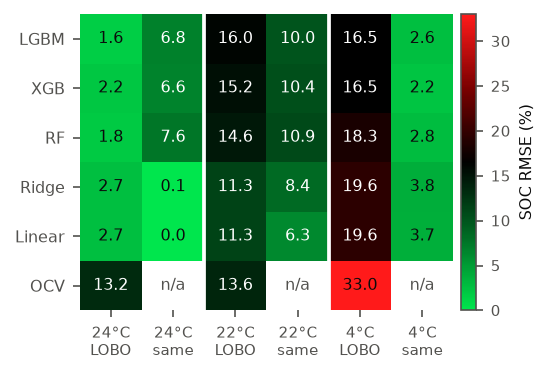

In [8]:
m = pd.read_csv(RESULTS / "soc_ablation.csv")
m = m[(m.config == "A_paper_SOHk") | ((m.config == "baseline") & (m.model == "OCV"))]
temps = {"B0005": 24, "B0006": 24, "B0007": 24, "B0018": 24, "B0042": 22, "B0054": 4}
m["temp"] = m["held_out"].map(temps)
mods = ["LightGBM", "XGBoost", "RandomForest", "Ridge", "Linear", "OCV"]
short = {"LightGBM": "LGBM", "XGBoost": "XGB", "RandomForest": "RF", "Ridge": "Ridge", "Linear": "Linear", "OCV": "OCV"}
colsx = [(24, "LOBO"), (24, "SameCell"), (22, "LOBO"), (22, "SameCell"), (4, "LOBO"), (4, "SameCell")]
M = np.full((len(mods), len(colsx)), np.nan)
for i, md in enumerate(mods):
    for j, (tt, pr) in enumerate(colsx):
        sel = m[(m.model == md) & (m.temp == tt) & (m.protocol == pr)]
        if len(sel): M[i, j] = sel["RMSE"].mean()
seq = LinearSegmentedColormap.from_list("gkr", ["#00e64d", "#006b24", "#000000", "#7a0000", "#ff1a1a"])
fig, a1 = plt.subplots(figsize=(COL1, 2.35)); a1.grid(False)
vmax = np.nanmax(M)
im = a1.imshow(M, cmap=seq, vmin=0, vmax=vmax, aspect="auto")
a1.set_xticks(range(len(colsx))); a1.set_xticklabels([f"{tt}°C\n{'LOBO' if p == 'LOBO' else 'same'}" for tt, p in colsx], fontsize=7)
a1.set_yticks(range(len(mods))); a1.set_yticklabels([short[x] for x in mods], fontsize=7.5)
for i in range(len(mods)):
    for j in range(len(colsx)):
        v = M[i, j]
        a1.text(j, i, "n/a" if np.isnan(v) else f"{v:.1f}", ha="center", va="center", fontsize=7.5,
                color=INK2 if np.isnan(v) else ("#ffffff" if 0.18 < v / vmax < 0.88 else INK))
for x in (1.5, 3.5):
    a1.axvline(x, color="#ffffff", lw=1.8)
for s_ in a1.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=a1, fraction=0.05, pad=0.02); cb.set_label("SOC RMSE (%)", fontsize=7.5); cb.ax.tick_params(labelsize=7)
fig.tight_layout(pad=0.2); save(fig, "fig_soc_heatmap.png")

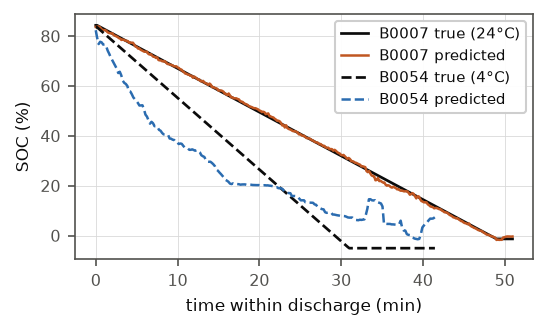

In [9]:
meta, _ = soc_load_meta()
tab = soc_build_table(meta)
cc = SOC_FEATSETS["A_paper_SOHk"]
fig, a2 = plt.subplots(figsize=(COL1, 2.05))
for cell in ("B0007", "B0054"):
    tr, te = tab[tab.battery_id != cell], tab[tab.battery_id == cell]
    mdl = soc_models()["XGBoost"]; mdl.fit(tr[cc].to_numpy(float), tr["soc"].to_numpy())
    cyc = sorted(te["cycle"].unique())[len(te["cycle"].unique()) // 2]
    d = te[te.cycle == cyc].sort_values("t")
    ls = "-" if cell == "B0007" else "--"
    a2.plot(d["t"] / 60, d["soc"], color=INK, lw=1.3, ls=ls, label=f"{cell} true ({temps[cell]}°C)")
    a2.plot(d["t"] / 60, mdl.predict(d[cc].to_numpy(float)), color=TCOL[float(temps[cell])], lw=1.2, ls=ls, label=f"{cell} predicted")
a2.set_xlabel("time within discharge (min)"); a2.set_ylabel("SOC (%)")
a2.legend(fontsize=7, loc="upper right", handlelength=1.8, framealpha=0.95)
fig.tight_layout(pad=0.2); save(fig, "fig_soc_traces.png")

### Fig. 8 — conformal bands on held-out B0005 (R1-5)

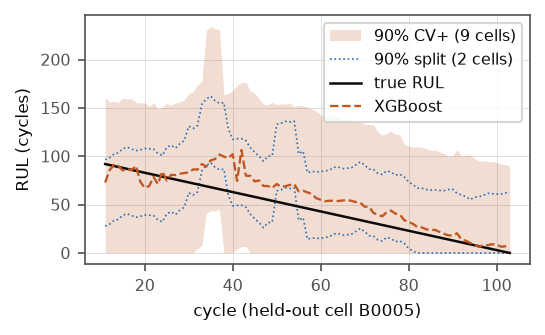

In [10]:
bnd = pd.read_csv(RESULTS / "final_conformal_bands_xgb.csv")
g = bnd[(bnd.method == "cvplus") & (bnd.battery == "B0005")].sort_values("cycle")
g2 = bnd[(bnd.method == "split2") & (bnd.battery == "B0005")].sort_values("cycle")
fig, ax = plt.subplots(figsize=(COL1, 2.1))
ax.fill_between(g["cycle"], g["lo"], g["hi"], color="#c05621", alpha=0.2, lw=0, label="90% CV+ (9 cells)")
ax.plot(g2["cycle"], g2["lo"], color="#2b6cb0", lw=0.8, ls=":", label="90% split (2 cells)")
ax.plot(g2["cycle"], g2["hi"], color="#2b6cb0", lw=0.8, ls=":")
ax.plot(g["cycle"], g["rul_true"], color=INK, lw=1.2, label="true RUL")
ax.plot(g["cycle"], g["rul_pred"], color="#c05621", lw=1.1, ls="--", label="XGBoost")
ax.set_xlabel("cycle (held-out cell B0005)"); ax.set_ylabel("RUL (cycles)"); ax.legend(loc="upper right")
fig.tight_layout(pad=0.3); save(fig, "fig_conformal.png")